In [1]:
from collections import deque

# Descripción de los estados
estados = {
    "S0": "Sueño irregular",
    "S1": "Rutina establecida",
    "S2": "Ambiente adecuado",
    "S3": "Rutina y ambiente adecuados",
    "S4": "Descanso adecuado",
    "S5": "Dificultad de sueño persistente"
}

# Cada transición incluye el destino y la acción o resultado observado.
grafo = {
    "S0": [
        ("S1", "Establecer rutina"),
        ("S2", "Adecuar ambiente")
    ],
    "S1": [
        ("S3", "Adecuar ambiente")
    ],
    "S2": [
        ("S3", "Establecer rutina")
    ],
    "S3": [
        ("S5", "La dificultad continúa"),
        ("S4", "Se observa mejora")
    ],
    "S4": [],
    "S5": []
}

inicio = "S0"
objetivo = "S4"

# Restricciones:
# Solo se recorren las transiciones definidas.
# S4 y S5 no tienen salidas.
# Las salidas de S3 representan posibles resultados observados.

In [2]:
def buscar_bfs(grafo, inicio, objetivo):
    # Guardamos el estado, el camino y sus transiciones.
    cola = deque([(inicio, [inicio], [])])
    descubiertos = {inicio}
    explorados = []

    while cola:
        actual, camino, pasos = cola.popleft()
        explorados.append(actual)

        print(f"Explorando {actual}: {estados[actual]}")

        if actual == objetivo:
            return camino, pasos, explorados

        for siguiente, operador in grafo[actual]:
            if siguiente not in descubiertos:
                descubiertos.add(siguiente)

                cola.append((
                    siguiente,
                    camino + [siguiente],
                    pasos + [(actual, operador, siguiente)]
                ))

    # Si se agotan los estados, no existe un camino al objetivo.
    return None, [], explorados


camino, pasos, explorados = buscar_bfs(grafo, inicio, objetivo)

Explorando S0: Sueño irregular
Explorando S1: Rutina establecida
Explorando S2: Ambiente adecuado
Explorando S3: Rutina y ambiente adecuados
Explorando S5: Dificultad de sueño persistente
Explorando S4: Descanso adecuado


In [3]:
print("\nRESULTADOS")
print("Orden de exploración:", " → ".join(explorados))

if camino is not None:
    print("Camino encontrado:", " → ".join(camino))
    print("Número de transiciones:", len(pasos))

    print("\nDetalle del recorrido:")
    for origen, operador, destino in pasos:
        print(f"{origen} → {destino}: {operador}")
else:
    print("No se encontró un camino hacia el objetivo.")


RESULTADOS
Orden de exploración: S0 → S1 → S2 → S3 → S5 → S4
Camino encontrado: S0 → S1 → S3 → S4
Número de transiciones: 3

Detalle del recorrido:
S0 → S1: Establecer rutina
S1 → S3: Adecuar ambiente
S3 → S4: Se observa mejora


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline

# Semilla para obtener los mismos datos al ejecutar nuevamente.
rng = np.random.default_rng(42)

edad = rng.uniform(3, 12, 120)

# Supuesto de simulación:
# 50 minutos a los 3 meses y 60 minutos a los 12 meses.
# Se agrega variación para evitar una relación perfecta.
duracion = 50 + (10 / 9) * (edad - 3) + rng.normal(0, 3, 120)

datos = pd.DataFrame({
    "edad_meses": edad,
    "duracion_ciclo_min": duracion
})

print("Cantidad de registros:", len(datos))
print("Valores faltantes:", datos.isna().sum().sum())
display(datos.head().round(2))

Cantidad de registros: 120
Valores faltantes: 0


,edad_meses,duracion_ciclo_min
0,9.97,62.54
1,6.95,53.67
2,10.73,55.52
3,9.28,57.51
4,3.85,51.60


In [5]:
X = datos[["edad_meses"]]
y = datos["duracion_ciclo_min"]

# 80 % para entrenar y 20 % para evaluar.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# No necesitamos escalar porque usamos una sola variable
# numérica con regresión lineal sin regularización.
modelo = Pipeline([
    ("regresion", LinearRegression())
])

modelo.fit(X_train, y_train)

print("Registros de entrenamiento:", len(X_train))
print("Registros de prueba:", len(X_test))

Registros de entrenamiento: 96
Registros de prueba: 24


In [6]:
predicciones = modelo.predict(X_test)

mae = mean_absolute_error(y_test, predicciones)
r2 = r2_score(y_test, predicciones)

# Referencia básica: predecir siempre el promedio de entrenamiento.
modelo_base = DummyRegressor(strategy="mean")
modelo_base.fit(X_train, y_train)
predicciones_base = modelo_base.predict(X_test)

mae_base = mean_absolute_error(y_test, predicciones_base)

print(f"MAE de la regresión: {mae:.2f} minutos")
print(f"MAE del modelo base: {mae_base:.2f} minutos")
print(f"R² de la regresión: {r2:.3f}")

if mae < mae_base:
    print("La regresión tuvo menor error que predecir el promedio.")
else:
    print("La regresión no mejoró la predicción del promedio.")

resultados = pd.DataFrame({
    "Edad (meses)": X_test["edad_meses"].to_numpy(),
    "Valor simulado (min)": y_test.to_numpy(),
    "Predicción (min)": predicciones
})

display(resultados.head(10).round(2))

MAE de la regresión: 2.49 minutos
MAE del modelo base: 3.90 minutos
R² de la regresión: 0.568
La regresión tuvo menor error que predecir el promedio.


,Edad (meses),Valor simulado (min),Predicción (min)
0,10.49,64.71,58.00
1,5.59,50.17,53.07
2,3.85,51.60,51.31
3,10.03,54.13,57.53
4,7.20,52.23,54.69
5,8.71,55.11,56.21
6,5.11,51.80,52.58
7,6.34,51.79,53.82
8,6.93,52.87,54.42
9,5.45,53.41,52.93


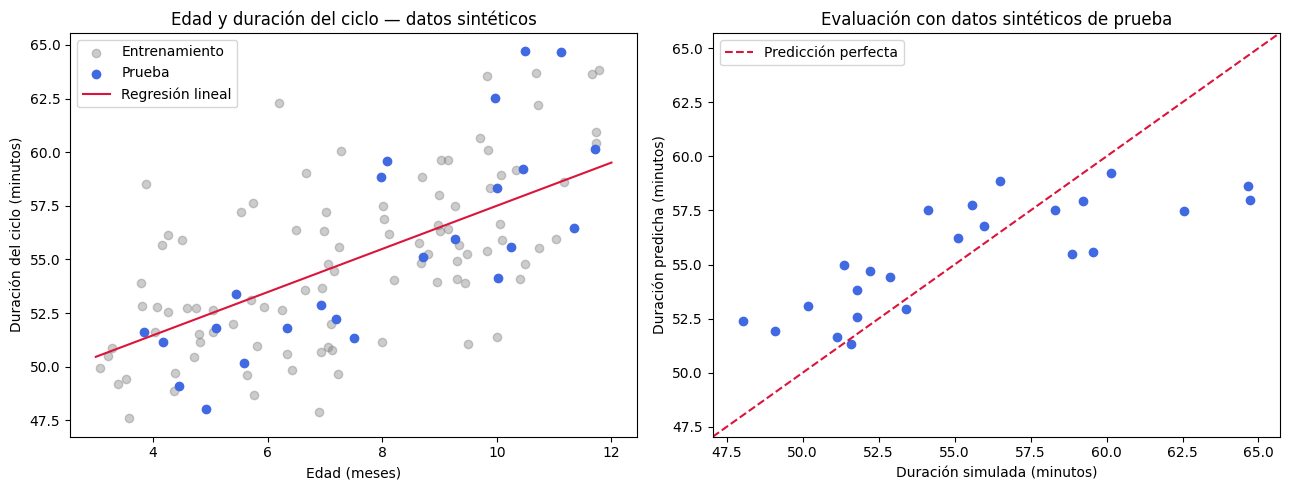

In [7]:
# Edades ordenadas para dibujar la recta del modelo.
edades_grafico = pd.DataFrame({
    "edad_meses": np.linspace(3, 12, 100)
})

duraciones_grafico = modelo.predict(edades_grafico)

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))

# Gráfico 1: relación entre edad y duración.
ejes[0].scatter(
    X_train["edad_meses"], y_train,
    alpha=0.4, color="gray", label="Entrenamiento"
)

ejes[0].scatter(
    X_test["edad_meses"], y_test,
    color="royalblue", label="Prueba"
)

ejes[0].plot(
    edades_grafico["edad_meses"], duraciones_grafico,
    color="crimson", label="Regresión lineal"
)

ejes[0].set_title("Edad y duración del ciclo — datos sintéticos")
ejes[0].set_xlabel("Edad (meses)")
ejes[0].set_ylabel("Duración del ciclo (minutos)")
ejes[0].legend()

# Gráfico 2: valores de prueba frente a sus predicciones.
ejes[1].scatter(y_test, predicciones, color="royalblue")

limite_min = min(y_test.min(), predicciones.min()) - 1
limite_max = max(y_test.max(), predicciones.max()) + 1

ejes[1].plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "--", color="crimson", label="Predicción perfecta"
)

ejes[1].set_xlim(limite_min, limite_max)
ejes[1].set_ylim(limite_min, limite_max)
ejes[1].set_title("Evaluación con datos sintéticos de prueba")
ejes[1].set_xlabel("Duración simulada (minutos)")
ejes[1].set_ylabel("Duración predicha (minutos)")
ejes[1].legend()

plt.tight_layout()
plt.show()

In [8]:
# Puedes cambiar esta edad por otra entre 3 y 12 meses.
edad_consulta = 6

if 3 <= edad_consulta <= 12:
    nuevo_registro = pd.DataFrame({
        "edad_meses": [edad_consulta]
    })

    estimacion = modelo.predict(nuevo_registro)[0]

    print(f"Edad: {edad_consulta} meses")
    print(f"Duración estimada del ciclo: {estimacion:.2f} minutos")
    print("Resultado del modelo entrenado con datos sintéticos.")
else:
    print("Ingresa una edad entre 3 y 12 meses.")

Edad: 6 meses
Duración estimada del ciclo: 53.48 minutos
Resultado del modelo entrenado con datos sintéticos.
